# Model FCOS



In [ ]:
import os, io, json, gc, math, time, random, shutil, hashlib, sys
from collections import defaultdict
from contextlib import redirect_stdout
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import torchvision
from PIL import Image
from tqdm import tqdm
from IPython.display import display
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import fcos_resnet50_fpn, FCOS_ResNet50_FPN_Weights
from torchvision.ops import complete_box_iou_loss
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import torchvision.models.detection.fcos as fcos_module

In [ ]:
ROOT = Path(Path('..').resolve())
DATA = ROOT / 'datasets' / 'multiple-object-video-detection-hw-2-ucu-ai-2026'
FOLDS_CSV = ROOT / 'shared/sequence_folds.csv'
SOURCE = ROOT / 'fcos/fcos_backup_new_account'
OUT = ROOT / 'fcos'
BACKUP = ROOT / 'fcos/fcos_backup'
os.chdir(ROOT); sys.path.insert(0, str(ROOT / 'shared')); sys.path.insert(0, str(ROOT / 'fcos'))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'CUDA GPU is required for this training run'
AMP = True
NUM_WORKERS = 2

In [1]:
assert (DATA / 'train' / 'annotations_coco.json').is_file(), DATA
assert (DATA / 'val' / 'annotations_coco.json').is_file(), DATA
assert FOLDS_CSV.is_file(), FOLDS_CSV
assert SOURCE.is_dir(), f'Checkpoint backup folder not found: {SOURCE}'
OUT.mkdir(parents=True, exist_ok=True)
BACKUP.mkdir(parents=True, exist_ok=True)
print('GPU:', torch.cuda.get_device_name(0))
print('torch:',torch.__version__, '| torchvision:',torchvision.__version__)
print('Dataset:',DATA)
print('Fold CSV:',FOLDS_CSV)
print('Source checkpoints:',SOURCE)
print('New results:',OUT)

GPU: NVIDIA GeForce RTX 5070
torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
Dataset: E:\ucu_hw2\datasets\multiple-object-video-detection-hw-2-ucu-ai-2026
Fold CSV: E:\ucu_hw2\shared\sequence_folds.csv
Source checkpoints: E:\ucu_hw2\fcos\fcos_backup_new_account
New results: E:\ucu_hw2\fcos


### Dataset and exact fold verification

In [ ]:
train_data = json.loads((DATA / 'train' / 'annotations_coco.json').read_text(encoding='utf-8'))
val_data = json.loads((DATA / 'val' / 'annotations_coco.json').read_text(encoding='utf-8'))
dataset_path = str(DATA)
CATEGORY_NAMES = {category['id']: category['name'] for category in train_data['categories']}
n_folds = 5

In [ ]:
train_images_df = pd.DataFrame(train_data['images']).sort_values(['video','frame_id']).reset_index(drop=True)
train_images_df['Frame Position'] = train_images_df.groupby('video').cumcount()
subsampled_images_df = train_images_df.loc[train_images_df['Frame Position'] % 5 == 0].copy()
folds = pd.read_csv(FOLDS_CSV)
assert {'id','Fold','video','frame_id','file_name'}.issubset(folds.columns), 'Unexpected fold CSV columns'
assert folds['id'].is_unique, 'Duplicate frame id in folds'
assert set(folds['id']) == set(subsampled_images_df['id']), 'Folds contain different sampled frames'
assert folds.groupby('video')['Fold'].nunique().max() == 1, 'Video leakage across folds'
assert set(folds['Fold']) == set(range(n_folds)), 'Fold labels must be 0..4'
check = folds.merge(subsampled_images_df[['id','video','frame_id','file_name']], on='id', suffixes=('', '_coco'))
assert len(check) == len(folds)
for field in ('video','frame_id','file_name'):
    assert (check[field] == check[field + '_coco']).all(), f'Fold CSV mismatch: {field}'

In [ ]:
def group_kfold(groups, n_splits):
    unique_groups, group_index = np.unique(groups, return_inverse=True)
    n_per_group = np.bincount(group_index)
    fold_sizes, group_to_fold = np.zeros(n_splits), np.zeros(len(unique_groups), dtype=int)
    for group in np.argsort(n_per_group)[::-1]:
        k = int(np.argmin(fold_sizes)); fold_sizes[k] += n_per_group[group]; group_to_fold[group] = k
    return group_to_fold[group_index]

In [2]:
expected = subsampled_images_df[['id','video']].copy()
expected['Fold'] = group_kfold(expected['video'].values, n_folds)
fold_comparison = folds[['id','Fold']].merge(expected[['id','Fold']], on='id', suffixes=('_disk','_original'))
assert (len(fold_comparison) == len(expected)
        and (fold_comparison.Fold_disk == fold_comparison.Fold_original).all()), (
    'Local CSV fold numbers differ from original FCOS Colab folds. STOP: do not resume wrong data split.')
cv_images_df = folds[['id','Fold','video','frame_id','file_name']].copy()
print('Validated:',len(cv_images_df),'frames,',cv_images_df.video.nunique(),'videos, folds:',
      cv_images_df.groupby('Fold').size().to_dict())

Validated: 4868 frames, 56 videos, folds: {0: 981, 1: 979, 2: 963, 3: 974, 4: 971}


In [3]:
%%writefile fcos_data.py
import os
import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset
from collections import defaultdict

Overwriting fcos_data.py


In [ ]:
%%writefile -a fcos_data.py

class VisDroneDataset(Dataset):
    def __init__(self, dataset_path, split, coco_data, image_ids=None, augment=False):
      self.dataset_path = dataset_path
      self.split = split
      self.augment = augment

      self.images = coco_data["images"]

      if image_ids is not None:
          selected_ids = set(image_ids)
          self.images = [image for image in self.images if image["id"] in selected_ids]

      self.annotations = defaultdict(list)
      self.ignore_annotations = defaultdict(set)
      own_ids = {image["id"] for image in self.images}

      for annotation in coco_data["annotations"]:
          image_id = annotation["image_id"]
          if image_id not in own_ids:
              continue

          if annotation["iscrowd"] == 0:
              self.annotations[image_id].append(annotation)
          else:
              self.ignore_annotations[image_id].add(tuple(annotation["bbox"]))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_info = self.images[index]

        image_path = os.path.join(self.dataset_path, self.split, image_info["file_name"])
        image = Image.open(image_path).convert("RGB")
        image_width, image_height = image.size

        boxes = []
        labels = []

        for annotation in self.annotations[image_info["id"]]:
            x, y, width, height = annotation["bbox"]

            xmin = max(0, x)
            ymin = max(0, y)
            xmax = min(image_width, x + width)
            ymax = min(image_height, y + height)

            if xmax <= xmin or ymax <= ymin:
                continue

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(annotation["category_id"])

        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(labels, dtype=torch.int64)

        image = np.array(image)
        image = torch.from_numpy(image).permute(2, 0, 1)
        image = image.float() / 255.0

        ignored_boxes = []

        for x, y, width, height in self.ignore_annotations[image_info["id"]]:
            xmin = max(0, x)
            ymin = max(0, y)
            xmax = min(image_width, x + width)
            ymax = min(image_height, y + height)

            if xmax > xmin and ymax > ymin:
                ignored_boxes.append([xmin, ymin, xmax, ymax])

        ignored_boxes = torch.tensor(ignored_boxes, dtype=torch.float32).reshape(-1, 4)

        if self.augment and torch.rand(1).item() < 0.5:
          image = torch.flip(image, dims=[2])

          if len(boxes) > 0:
              old_xmin = boxes[:, 0].clone()
              old_xmax = boxes[:, 2].clone()

              boxes[:, 0] = image_width - old_xmax
              boxes[:, 2] = image_width - old_xmin

          if len(ignored_boxes) > 0:
              old_xmin = ignored_boxes[:, 0].clone()
              old_xmax = ignored_boxes[:, 2].clone()

              ignored_boxes[:, 0] = image_width - old_xmax
              ignored_boxes[:, 2] = image_width - old_xmin

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(image_info["id"]),
            "ignored_boxes": ignored_boxes}

        return image, target

In [ ]:
%%writefile -a fcos_data.py


class FCOSDataset(VisDroneDataset):
    def __getitem__(self, index):
        image, target = super().__getitem__(index)
        mean = image.new_tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        if self.augment:
            for x1, y1, x2, y2 in target['ignored_boxes'].int().tolist():
                image[:, max(0,y1):min(image.shape[1],y2),
                      max(0,x1):min(image.shape[2],x2)] = mean
        return image, target


def collate(batch):
    return tuple(zip(*batch))

In [ ]:
from fcos_data import VisDroneDataset, FCOSDataset

def fold_data(fold_id):
    train_ids = cv_images_df.loc[cv_images_df['Fold'] != fold_id, 'id']
    val_ids = cv_images_df.loc[cv_images_df['Fold'] == fold_id, 'id']
    train_ds = FCOSDataset(dataset_path, 'train', train_data, train_ids, augment=True)
    val_ds = FCOSDataset(dataset_path, 'train', train_data, val_ids, augment=False)
    assert set(image_info['video'] for image_info in train_ds.images).isdisjoint(
        image_info['video'] for image_info in val_ds.images)
    return train_ds, val_ds

In [ ]:
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

from fcos_data import collate
def make_loader(dataset, batch_size, shuffle, workers=NUM_WORKERS):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=workers,
                      collate_fn=collate, pin_memory=AMP, persistent_workers=False)

In [ ]:
def safe_replace(temp_path, path, tries=30):
    for attempt in range(tries):
        try:
            return os.replace(temp_path, path)
        except PermissionError:
            if attempt == tries - 1: raise
            time.sleep(2)

def atomic_checkpoint(path, state):
    path = Path(path)
    temp_path = path.with_name(path.name + '.tmp')
    torch.save(state, temp_path)
    safe_replace(temp_path, path)

def atomic_text(path, value):
    path = Path(path)
    temp_path = path.with_name(path.name + '.tmp')
    temp_path.write_text(value, encoding='utf-8')
    safe_replace(temp_path, path)

def backup_file(path):
    path = Path(path)
    backup_path = BACKUP / path.relative_to(OUT)
    backup_path.parent.mkdir(parents=True, exist_ok=True)
    temp_path = backup_path.with_name(backup_path.name + '.tmp')
    shutil.copy2(path, temp_path)
    safe_replace(temp_path, backup_path)

In [ ]:
def source_invalid(run_dir):
    history_file = run_dir / 'history.csv'
    return history_file.exists() and bool((pd.read_csv(history_file)['mAP'] < 0).any())

def restore_sources():
    skipped = sorted({history_file.parent for history_file in SOURCE.rglob('history.csv')
                      if source_invalid(history_file.parent)})
    for run_dir in skipped:
        print('NOT restored (invalid mAP=-1, will retrain from scratch):', run_dir.relative_to(SOURCE))
    for source_file in SOURCE.rglob('*'):
        if not source_file.is_file() or source_file.name not in ('last.pth','best.pth','history.csv','result.json'):
            continue
        if source_file.parent in skipped:
            continue
        target = OUT / source_file.relative_to(SOURCE)
        target.parent.mkdir(parents=True,exist_ok=True)
        if not target.exists(): shutil.copy2(source_file, target)
    print('Restored/preserved',len(list(OUT.rglob('*.pth'))),'checkpoints')

restore_sources()

### Model FCOS

In [ ]:
import torchvision.models.detection.fcos as fcos_module
from torchvision.models.detection import fcos_resnet50_fpn, FCOS_ResNet50_FPN_Weights
from torchvision.ops import complete_box_iou_loss
import torch.nn as nn

BASE = dict(name='F0_baseline', seed=42, epochs=6, bs=2, lr=0.005, wd=1e-4,
            warmup=500, min_size=720, max_size=1280, center_radius=1.5,
            box_loss='giou', score_thr=0.02, nms_thr=0.6, topk=1000,
            det_per_img=300, mask_ignore=True, trainable_layers=3)
_ORIGINAL_GIOU_LOSS = fcos_module.generalized_box_iou_loss

In [ ]:
def box_loss_function(kind):
    if kind == 'giou':
        return _ORIGINAL_GIOU_LOSS
    if kind == 'ciou':
        def ciou(pred_boxes, target_boxes, reduction='sum'):
            return complete_box_iou_loss(pred_boxes.float(), target_boxes.float(), reduction=reduction)
        return ciou
    raise ValueError(f'Unknown loss: {kind}')

#### FCOS model with a 9-class head

In [ ]:
def build_model(cfg):
    model = fcos_resnet50_fpn(
        weights=FCOS_ResNet50_FPN_Weights.DEFAULT,
        trainable_backbone_layers=cfg['trainable_layers'],
        min_size=cfg['min_size'], max_size=cfg['max_size'],
        center_sampling_radius=cfg['center_radius'],
        score_thresh=cfg['score_thr'], nms_thresh=cfg['nms_thr'],
        topk_candidates=cfg['topk'], detections_per_img=cfg['det_per_img'])
    classification_head = model.head.classification_head
    classification_head.cls_logits = nn.Conv2d(256, 9, kernel_size=3, padding=1)
    nn.init.normal_(classification_head.cls_logits.weight, std=0.01)
    nn.init.constant_(classification_head.cls_logits.bias, -math.log((1-0.01)/0.01))
    classification_head.num_classes = 9
    return model

def set_inference(model, score_thresh=None, nms_thresh=None, topk_candidates=None, detections_per_img=None):
    if score_thresh is not None:       model.score_thresh = score_thresh
    if nms_thresh is not None:         model.nms_thresh = nms_thresh
    if topk_candidates is not None:    model.topk_candidates = topk_candidates
    if detections_per_img is not None: model.detections_per_img = detections_per_img

#### COCO ground truth for a subset of images

In [ ]:
def make_gt(coco, ids):
    ids = set(int(image_id) for image_id in ids)
    annotations = []
    for annotation in coco["annotations"]:
        if annotation["image_id"] in ids:
            annotation = dict(annotation)
            annotation["area"] = float(annotation["bbox"][2] * annotation["bbox"][3])
            annotations.append(annotation)
    for k, annotation in enumerate(annotations): annotation["id"] = k + 1
    gt = COCO()
    gt.dataset = dict(info={}, licenses=[],
                      images=[image_info for image_info in coco["images"] if image_info["id"] in ids],
                      annotations=annotations, categories=coco["categories"])
    with redirect_stdout(io.StringIO()): gt.createIndex()
    return gt

#### Prediction

In [ ]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); predictions = []
    for batch_images, batch_targets in tqdm(loader, desc="predict", leave=False):
        with torch.autocast("cuda", enabled=AMP):
            outputs = model([image.to(DEVICE, non_blocking=True) for image in batch_images])
        for output, target in zip(outputs, batch_targets):
            predictions.append((int(target["image_id"]),
                                {k: v.float().cpu() if k != "labels" else v.cpu() for k, v in output.items()}))
    return predictions

#### COCO metrics

In [ ]:
def coco_metrics(preds, gt):
    detections = [dict(image_id=image_id, category_id=int(label),
                       bbox=[box[0], box[1], box[2] - box[0], box[3] - box[1]], score=float(score))
                  for image_id, prediction in preds
                  for box, score, label in zip(prediction["boxes"].tolist(), prediction["scores"],
                                               prediction["labels"])]
    keys = ["mAP", "AP50", "AP75", "APs", "APm", "APl", "AR"]
    if not detections: return {**{k: 0.0 for k in keys}, "per_class": {}}
    with redirect_stdout(io.StringIO()):
        coco_eval = COCOeval(gt, gt.loadRes(detections), "bbox")
        coco_eval.params.imgIds = sorted(gt.getImgIds()); coco_eval.params.maxDets = [1, 10, 100]
        coco_eval.evaluate(); coco_eval.accumulate(); coco_eval.summarize()
    assert coco_eval.stats[0] >= 0, 'COCOeval returned mAP=-1 (maxDets must contain 100)'
    stats = coco_eval.stats; precision = coco_eval.eval["precision"][:, :, :, 0, -1]
    per_class = {CATEGORY_NAMES[category_id]:
                     float(precision[:, :, category_index][precision[:, :, category_index] > -1].mean())
                     if (precision[:, :, category_index] > -1).any() else float("nan")
                 for category_index, category_id in enumerate(coco_eval.params.catIds)}
    return dict(mAP=stats[0], AP50=stats[1], AP75=stats[2], APs=stats[3], APm=stats[4], APl=stats[5], AR=stats[8],
                per_class=per_class)

#### Inference speed

In [ ]:
@torch.no_grad()
def measure_speed(model, dataset, n_images=40, n_warmup=10):
    model.eval(); timings = []
    for i in range(n_images + n_warmup):
        image = dataset[(i * 7) % len(dataset)][0].to(DEVICE)
        torch.cuda.synchronize(); start_time = time.perf_counter()
        with torch.autocast("cuda", enabled=AMP): model([image])
        torch.cuda.synchronize(); timings.append(time.perf_counter() - start_time)
    return 1000 * float(np.mean(timings[n_warmup:]))

#### Experiments

In [ ]:
EXPERIMENTS = [
    dict(name='F0_baseline'),
    dict(name='F1_ciou', box_loss='ciou'),
    dict(name='F2_radius_1_0', center_radius=1.0),
]

In [ ]:
for spec in EXPERIMENTS:
    cfg = {**BASE, **spec}
    for fold_id in range(n_folds):
        folder = OUT / cfg['name'] / f'fold_{fold_id}'
        if not (folder / 'result.json').exists():
            continue
        stored = json.loads((folder / 'result.json').read_text(encoding='utf-8'))['metrics']
        _, val_ds = fold_data(fold_id)
        model = build_model(cfg)
        model.load_state_dict(torch.load(folder / 'best.pth', map_location='cpu', weights_only=False)['model'])
        recomputed = coco_metrics(predict(model.to(DEVICE), make_loader(val_ds, cfg['bs'], False)),
                                  make_gt(train_data, [image_info['id'] for image_info in val_ds.images]))
        diff = max(abs(recomputed[k] - stored[k]) for k in ('mAP','AP50','AP75','APs','APm','APl'))
        print(f"{cfg['name']} fold_{fold_id}: stored mAP {stored['mAP']:.4f} | re-evaluated {recomputed['mAP']:.4f} | "
              f"max metric difference {diff:.4f}" + ('  <-- WARNING: evaluation differs' if diff > 0.005 else '  OK'))
        del model; gc.collect(); torch.cuda.empty_cache()

### Training 

In [ ]:
def save_checkpoint(path, state):
    temp_path = path.with_suffix('.tmp')
    torch.save(state, temp_path)
    safe_replace(temp_path, path)
    backup_file(path)

In [ ]:
def run_experiment(override, fold_id):
    cfg = {**BASE, **override}
    name = cfg['name']; run_dir = OUT / name / f'fold_{fold_id}'; run_dir.mkdir(parents=True, exist_ok=True)
    train_ds, val_ds = fold_data(fold_id)
    val_gt = make_gt(train_data, [image_info["id"] for image_info in val_ds.images])
    val_loader = make_loader(val_ds, cfg['bs'], False)
    result_path = run_dir / 'result.json'
    if result_path.exists():
        saved = json.loads(result_path.read_text())
        if saved.get('cfg') != cfg or saved.get('fold') != fold_id or not (run_dir/'best.pth').exists():
            raise RuntimeError(f'{name}: saved config differs. Move old run folder or change run name before retraining.')
        print(f'Already complete: {name} fold {fold_id} | best mAP {saved["metrics"]["mAP"]:.4f}')
        return saved
    seed_all(cfg['seed'])
    model = build_model(cfg).to(DEVICE)
    train_loader = make_loader(train_ds, cfg['bs'], True)
    params = [param for param in model.parameters() if param.requires_grad]
    optimizer = torch.optim.SGD(params, lr=cfg['lr'], momentum=0.9, weight_decay=cfg['wd'])
    total_steps = len(train_loader) * cfg['epochs']
    warmup = min(cfg['warmup'], max(1, total_steps // 5))
    def lr_factor(step):
        if step < warmup:
            return (step + 1) / warmup
        progress = min(1.0, (step - warmup) / max(1, total_steps - warmup))
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * progress))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    history, start, best_map, best_epoch = [], 0, -float('inf'), 0
    last_path = run_dir / 'last.pth'
    if last_path.exists():
        checkpoint = torch.load(last_path, map_location='cpu', weights_only=False)
        assert checkpoint['cfg'] == cfg, 'Checkpoint configuration changed; use a new run folder.'
        model.load_state_dict(checkpoint['model'])
        optimizer.load_state_dict(checkpoint['opt']); scheduler.load_state_dict(checkpoint['sched'])
        scaler.load_state_dict(checkpoint['scaler'])
        history, start = checkpoint['history'], checkpoint['epoch']
        best_map, best_epoch = checkpoint['best_map'], checkpoint['best_epoch']
        print(f'Resumed {name} from epoch {start}/{cfg["epochs"]}')
    try:
        for epoch in range(start, cfg['epochs']):
            model.train(); loss_sums = defaultdict(float); batches = 0; start_time = time.perf_counter()
            for batch_images, batch_targets in tqdm(train_loader, desc=f'{name} · epoch {epoch + 1}/{cfg["epochs"]}'):
                batch_images = [image.to(DEVICE, non_blocking=True) for image in batch_images]
                targets = [{'boxes': target['boxes'].to(DEVICE), 'labels': target['labels'].to(DEVICE)}
                           for target in batch_targets]
                optimizer.zero_grad(set_to_none=True)
                previous = fcos_module.generalized_box_iou_loss
                try:
                    fcos_module.generalized_box_iou_loss = box_loss_function(cfg['box_loss'])
                    with torch.autocast('cuda', enabled=AMP):
                        losses = model(batch_images, targets)
                        loss = sum(losses.values())
                finally:
                    fcos_module.generalized_box_iou_loss = previous
                if not torch.isfinite(loss):
                    raise RuntimeError(f'Nonfinite training loss: {name} epoch {epoch+1}')
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(params, 10.0)
                scaler.step(optimizer); scaler.update(); scheduler.step()
                for k, v in losses.items(): loss_sums[k] += float(v.detach().cpu())
                batches += 1
            metrics = coco_metrics(predict(model, val_loader), val_gt)
            entry = dict(epoch=epoch+1, lr=optimizer.param_groups[0]['lr'],
                         train_loss=sum(loss_sums.values())/max(1,batches),
                         seconds=time.perf_counter()-start_time,
                         **{k: metrics[k] for k in ['mAP','AP50','AP75','APs','APm','APl']})
            history.append(entry)
            improved = metrics['mAP'] > best_map
            if improved:
                best_map, best_epoch = metrics['mAP'], epoch+1
                save_checkpoint(run_dir/'best.pth', dict(model=model.state_dict(), cfg=cfg,
                                                         epoch=best_epoch, metrics=metrics))
            save_checkpoint(last_path, dict(model=model.state_dict(), opt=optimizer.state_dict(),
                                           sched=scheduler.state_dict(), scaler=scaler.state_dict(),
                                           history=history, epoch=epoch+1, best_map=best_map,
                                           best_epoch=best_epoch, cfg=cfg))
            atomic_text(run_dir/'history.csv', pd.DataFrame(history).to_csv(index=False))
            backup_file(run_dir/'history.csv')
            print(f'{name} | epoch {epoch+1:02d}/{cfg["epochs"]} | loss {entry["train_loss"]:.4f} '
                  f'| mAP {metrics["mAP"]:.4f} | AP50 {metrics["AP50"]:.4f} | AP_small {metrics["APs"]:.4f} '
                  f'| best {best_map:.4f} (epoch {best_epoch})')
        best_checkpoint = torch.load(run_dir/'best.pth', map_location='cpu', weights_only=False)
        model.load_state_dict(best_checkpoint['model'])
        metrics = best_checkpoint['metrics']
        speed = measure_speed(model, val_ds)
        result = dict(name=name, fold=fold_id, cfg=cfg, best_epoch=best_epoch, history=history,
                      metrics=metrics, ms_per_img=speed,
                      n_params_M=sum(param.numel() for param in model.parameters())/1e6,
                      train_frames=len(train_ds), val_frames=len(val_ds))
        atomic_text(result_path, json.dumps(result, indent=2, default=float))
        backup_file(result_path)
        print(f'COMPLETED {name}: best epoch {best_epoch}, mAP {metrics["mAP"]:.4f}, {speed:.1f} ms/image')
        return result
    finally:
        del model, optimizer
        gc.collect(); torch.cuda.empty_cache()

In [ ]:
def load_model(name, fold_id):
    folder = OUT/name/f'fold_{fold_id}'
    result = json.loads((folder/'result.json').read_text())
    model = build_model(result['cfg'])
    checkpoint = torch.load(folder/'best.pth', map_location='cpu', weights_only=False)
    model.load_state_dict(checkpoint['model'])
    return model.to(DEVICE).eval()

### Run experiments

In [ ]:
results = {}
for spec in EXPERIMENTS:
    name = spec['name']
    results[name] = []
    for fold_id in range(n_folds):
        print(f'\n{name} | fold {fold_id + 1}/{n_folds}')
        result = run_experiment(spec, fold_id)
        results[name].append(result)
        print(f'{name} fold {fold_id}: mAP={result["metrics"]["mAP"]:.4f}, '
              f'AP50={result["metrics"]["AP50"]:.4f}, AP_small={result["metrics"]["APs"]:.4f}')

### Summary and official validation

In [ ]:
rows = []
for spec in EXPERIMENTS:
    name = spec['name']
    for fold_id in range(n_folds):
        fold_result = json.loads((OUT/name/f'fold_{fold_id}'/'result.json').read_text())
        rows.append(dict(run=name, fold=fold_id, box_loss=fold_result['cfg']['box_loss'],
                         center_radius=fold_result['cfg']['center_radius'],
                         best_epoch=fold_result['best_epoch'],
                         mAP=fold_result['metrics']['mAP'], AP50=fold_result['metrics']['AP50'],
                         AP_small=fold_result['metrics']['APs'], AP_medium=fold_result['metrics']['APm'],
                         AP_large=fold_result['metrics']['APl'], ms_per_img=fold_result['ms_per_img']))
all_folds = pd.DataFrame(rows)
all_folds.to_csv(OUT/'fold_results.csv', index=False)

,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_img,mAP_std,AP50_std,AP_small_std,AP_medium_std,AP_large_std,ms_per_img_std
run,,,,,,,,,,,,
F0_baseline,0.1969,0.3790,0.0774,0.1803,0.3634,53.8134,0.0318,0.0514,0.0340,0.0138,0.0337,22.5409
F1_ciou,0.1969,0.3791,0.0759,0.1831,0.3690,28.4896,0.0314,0.0493,0.0340,0.0119,0.0395,0.3245
F2_radius_1_0,0.1960,0.3823,0.0754,0.1870,0.3516,29.1317,0.0303,0.0494,0.0307,0.0167,0.0286,0.6072


SEARCH RANGE: box loss = {GIoU, CIoU}; center radius = {1.0, 1.5}
SELECTED: F1_ciou | mean mAP: 0.1969 ± 0.0314
Representative checkpoint fold: 2


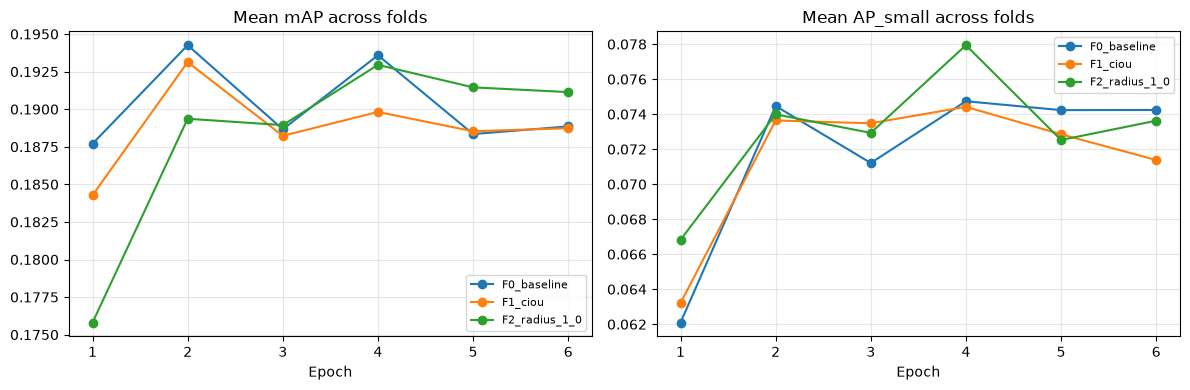

In [13]:
metrics_cols = ['mAP', 'AP50', 'AP_small', 'AP_medium', 'AP_large', 'ms_per_img']
means = all_folds.groupby('run')[metrics_cols].mean()
stds = all_folds.groupby('run')[metrics_cols].std()
summary = means.copy()
for col in metrics_cols:
    summary[col + '_std'] = stds[col]
summary.to_csv(OUT/'comparison_5fold.csv')
display(summary.round(4))
BEST = means['mAP'].idxmax()
BEST_FOLD = int(all_folds.loc[all_folds.run == BEST].sort_values('mAP', ascending=False).iloc[0]['fold'])
print('SEARCH RANGE: box loss = {GIoU, CIoU}; center radius = {1.0, 1.5}')
print(f'SELECTED: {BEST} | mean mAP: {means.loc[BEST,"mAP"]:.4f} ± {stds.loc[BEST,"mAP"]:.4f}')
print('Representative checkpoint fold:', BEST_FOLD)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for spec in EXPERIMENTS:
    name = spec['name']
    histories = [pd.read_csv(OUT/name/f'fold_{fold_id}'/'history.csv') for fold_id in range(n_folds)]
    for axis, metric in zip(ax, ['mAP', 'APs']):
        curve = pd.concat([history.set_index('epoch')[metric].rename(fold_id)
                           for fold_id, history in enumerate(histories)], axis=1)
        axis.plot(curve.index, curve.mean(axis=1), marker='o', label=name)
ax[0].set_title('Mean mAP across folds'); ax[1].set_title('Mean AP_small across folds')
for axis in ax:
    axis.set_xlabel('Epoch'); axis.grid(alpha=.3); axis.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT/'training_curves_5fold.png', dpi=160); plt.show()

In [ ]:
official_ds = FCOSDataset(dataset_path, 'val', val_data,
                          [image_info['id'] for image_info in val_data['images']], augment=False)
official_gt = make_gt(val_data, [image_info['id'] for image_info in val_data['images']])
official_results = {}

In [ ]:
for name in dict.fromkeys(['F0_baseline', BEST]):
    chosen = all_folds.loc[all_folds.run == name].sort_values('mAP', ascending=False).iloc[0]
    selected_fold = int(chosen['fold'])
    model = load_model(name, selected_fold)
    official_results[name] = coco_metrics(predict(model, make_loader(official_ds, 2, False, workers=0)), official_gt)
    print(name, f'(fold {selected_fold})',
          {k: round(official_results[name][k], 4) for k in ('mAP', 'AP50', 'APs', 'APm', 'APl')})
    del model; gc.collect(); torch.cuda.empty_cache()
(OUT/'official_validation.json').write_text(json.dumps(official_results, indent=2))

## Final Model Evaluation and Testing

For FCOS and Faster R-CNN, we use the same final_evaluation.py file to evaluate both models with the same ground truth, COCOeval settings, and speed measurement protocol.

In [ ]:
import os, sys
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = Path(os.environ.get('UCU_HW2_ROOT', Path('..').resolve()))
os.environ['UCU_HW2_ROOT'] = str(ROOT)
sys.path.insert(0, str(ROOT / 'shared'))
import final_evaluation

MODEL = 'fcos'

In [1]:
print('GPU:', final_evaluation.gpu_status())
print('COCO evaluation config id:', final_evaluation.EVAL_ID, '| speed protocol id:', final_evaluation.SPEED_ID)
overlap = final_evaluation.overlap_check()
print({k: overlap[k] for k in ('shared_video_names', 'shared_source_flights', 'identical_files_train_val',
                               'identical_files_train_test', 'identical_files_val_test', 'test_labels_available')})

GPU: {'gpu': 'NVIDIA GeForce RTX 5070', 'utilization_pct': 1, 'memory_used_mib': 1331, 'memory_total_mib': 12227}
COCO evaluation config id: 639cae7b8a2dd79e | speed protocol id: 0eb0c2f5d2535e81
{'shared_video_names': [], 'shared_source_flights': [], 'identical_files_train_val': 0, 'identical_files_train_test': 0, 'identical_files_val_test': 0, 'test_labels_available': False}


In [2]:
inventory = final_evaluation.training_inventory()
final_evaluation.save_csv(inventory, final_evaluation.FINAL / 'audit' / 'training_inventory.csv')
model_inventory = inventory[inventory.model == final_evaluation.MODELS[MODEL]['label']]
display(model_inventory[['experiment', 'fold', 'status', 'completed_epochs', 'best_epoch', 'cv_map',
                         'trained_on', 'issues']].round(4))
assert (model_inventory.status == 'complete').all(), 'incomplete or inconsistent run: see the issues column'

,experiment,fold,status,completed_epochs,best_epoch,cv_map,trained_on,issues
15,F0_baseline,0,complete,6,4,0.2196,Colab run had mAP=-1 (old maxDets bug); retrai...,none
16,F0_baseline,1,complete,6,4,0.2121,"Colab (restored from read-only backup, identic...",none
17,F0_baseline,2,complete,6,2,0.2092,"Colab (restored from read-only backup, identic...",none
18,F0_baseline,3,complete,6,2,0.2024,"Colab (restored from read-only backup, identic...",none
19,F0_baseline,4,complete,6,2,0.1412,Colab epochs 1-3; resumed locally from last.pth,none
20,F1_ciou,0,complete,6,4,0.2141,local RTX 5070,none
21,F1_ciou,1,complete,6,2,0.2088,local RTX 5070,none
22,F1_ciou,2,complete,6,2,0.2196,local RTX 5070,none
23,F1_ciou,3,complete,6,3,0.2001,local RTX 5070,none
24,F1_ciou,4,complete,6,2,0.1422,local; interrupted after epoch 3 and resumed l...,none


### Official validation metrics


In [3]:
official, checks = final_evaluation.run_official_evaluation(MODEL,
                                                            final_evaluation.VERIFY[MODEL])
print('Stored vs recomputed (identical checkpoints):')
display(checks[['experiment', 'fold', 'stored_mAP', 'recomputed_mAP', 'max_abs_diff_all_metrics', 'agrees']].round(5))
display(official.pivot(index='experiment', columns='fold', values='mAP').round(4))

FCOS F0_baseline fold 1: official-val mAP 0.1762 (2.6 min)


FCOS F0_baseline fold 2: official-val mAP 0.1615 (2.5 min)


FCOS F0_baseline fold 3: official-val mAP 0.1802 (2.5 min)


FCOS F0_baseline fold 4: official-val mAP 0.1776 (2.5 min)


FCOS F1_ciou fold 0: official-val mAP 0.1709 (2.5 min)


FCOS F1_ciou fold 1: official-val mAP 0.1830 (2.5 min)


... (6 outputs left out)

FCOS F2_radius_1_0 fold 3: official-val mAP 0.1770 (3.1 min)


FCOS F2_radius_1_0 fold 4: official-val mAP 0.1858 (2.9 min)
Stored vs recomputed (identical checkpoints):


,experiment,fold,stored_mAP,recomputed_mAP,max_abs_diff_all_metrics,agrees
0,F0_baseline,0,0.17369,0.17369,0.0,True
1,F1_ciou,2,0.17084,0.17084,0.0,True


fold,0,1,2,3,4
experiment,,,,,
F0_baseline,0.1737,0.1762,0.1615,0.1802,0.1776
F1_ciou,0.1709,0.1830,0.1708,0.1912,0.1804
F2_radius_1_0,0.1823,0.1865,0.1923,0.1770,0.1858


### Inference speed

In [4]:
cv_mean_map = {experiment: sum(final_evaluation.load_result(MODEL, experiment, fold_id)['metrics']['mAP']
                               for fold_id in final_evaluation.FOLDS) / 5
               for experiment in final_evaluation.MODELS[MODEL]['experiments']}
BEST_CV_EXPERIMENT = max(cv_mean_map, key=cv_mean_map.get)
REPRESENTATIVE_FOLD = final_evaluation.representative_fold(official, BEST_CV_EXPERIMENT)
speed = final_evaluation.run_speed(MODEL, representative=(BEST_CV_EXPERIMENT, REPRESENTATIVE_FOLD))
display(speed.groupby(['experiment', 'batch_size', 'precision'])[['ms_per_image', 'fps']]
        .agg(['mean', 'std']).round(1))

ms_per_image        fps     
                                           mean  std  mean  std
experiment    batch_size precision                             
F0_baseline   1          amp_fp16          31.2  0.4  32.0  0.4
              4          amp_fp16          31.0  0.6  32.3  0.6
F1_ciou       1          amp_fp16          31.6  0.6  31.7  0.6
                         fp32              33.2  NaN  30.2  NaN
              4          amp_fp16          30.7  0.9  32.6  1.0
F2_radius_1_0 1          amp_fp16          29.2  0.6  34.3  0.7
              4          amp_fp16          29.3  0.6  34.2  0.7

### Fold-level metrics, mean ± std and selection

In [5]:
section = final_evaluation.model_section(MODEL)
summary = section['summary']
metric_columns = ['map', 'map_50', 'map_75', 'map_small', 'map_medium', 'map_large', 'ar', 'ms_per_image']
table = summary.set_index(['evaluation_split', 'experiment'])
display(pd.DataFrame({column: table[column + '_mean'].map('{:.4f}'.format) + ' ± '
                              + table[column + '_std'].map('{:.4f}'.format)
                      for column in metric_columns}))
print({k: section['selection'][k] for k in ('best_by_cv', 'best_by_official_val', 'agree', 'representative_fold')})

,,map,map_50,map_75,map_small,map_medium,map_large,ar,ms_per_image
evaluation_split,experiment,,,,,,,,
cv_out_of_fold,F0_baseline,0.1969 ± 0.0318,0.3790 ± 0.0514,0.1819 ± 0.0352,0.0774 ± 0.0340,0.1803 ± 0.0138,0.3634 ± 0.0337,0.3688 ± 0.0566,31.2312 ± 0.3886
official_val,F0_baseline,0.1738 ± 0.0073,0.3471 ± 0.0162,0.1534 ± 0.0044,0.0850 ± 0.0071,0.1562 ± 0.0074,0.3257 ± 0.0161,0.3922 ± 0.0077,31.2312 ± 0.3886
cv_out_of_fold,F1_ciou,0.1969 ± 0.0314,0.3791 ± 0.0493,0.1819 ± 0.0358,0.0759 ± 0.0340,0.1831 ± 0.0119,0.3690 ± 0.0395,0.3692 ± 0.0524,31.6005 ± 0.6413
official_val,F1_ciou,0.1793 ± 0.0087,0.3575 ± 0.0167,0.1586 ± 0.0085,0.0858 ± 0.0045,0.1584 ± 0.0089,0.3339 ± 0.0134,0.3965 ± 0.0115,31.6005 ± 0.6413
cv_out_of_fold,F2_radius_1_0,0.1960 ± 0.0303,0.3823 ± 0.0494,0.1794 ± 0.0353,0.0754 ± 0.0307,0.1870 ± 0.0167,0.3516 ± 0.0286,0.3735 ± 0.0520,29.1767 ± 0.5748
official_val,F2_radius_1_0,0.1848 ± 0.0056,0.3703 ± 0.0063,0.1619 ± 0.0097,0.0866 ± 0.0073,0.1618 ± 0.0060,0.3521 ± 0.0091,0.3892 ± 0.0136,29.1767 ± 0.5748


{'best_by_cv': 'F1_ciou', 'best_by_official_val': 'F2_radius_1_0', 'agree': False, 'representative_fold': 4}


### Inference tests and failure analysis


In [6]:
selection = section['selection']
failures = final_evaluation.failure_section(MODEL, selection['best_by_cv'],
                                            selection['representative_fold'])
print(f"{selection['best_by_cv']} fold {selection['representative_fold']} | "
      f"score threshold {failures['threshold']:.2f} |", failures['totals'])
display(pd.DataFrame(failures['recall_by_size']).round(3))
display(pd.DataFrame(failures['cases'])[['title', 'video', 'frame_id', 'n_gt', 'tp', 'missed', 'missed_small',
                                         'classification', 'localization', 'background']])

F1_ciou fold 4 | score threshold 0.50 | {'tp': 58760, 'duplicate': 1605, 'classification': 12086, 'localization': 6474, 'background': 12207, 'ignored': 9101, 'missed': 55372, 'n_gt': 114132}


,size,n_gt,missed,recall
0,small,21910,15591,0.288
1,medium,79357,37109,0.532
2,large,12865,2672,0.792


,title,video,frame_id,n_gt,tp,missed,missed_small,classification,localization,background
0,most missed small objects (false negatives),uav0000182_00000_v,190,57,14,43,30,7,1,8
1,most classification errors,uav0000182_00000_v,289,80,43,37,15,26,2,14
2,most localization errors,uav0000137_00458_v,115,111,56,55,0,6,15,17
3,most background false positives,uav0000305_00000_v,150,26,18,8,1,4,1,26
